# 05 - Liwa Precision Ag Machine Learning Baselines

**Arab Youth Space Hackathon 2026** | Team: ليوا الخضراء | Theme: Precision Agriculture & Crop Intelligence

This notebook trains Random Forest and Logistic Regression baselines using fused multi-sensor feature stacks (Sentinel-2 NDVI/SAVI/SI + Copernicus DEM Slope + EnMAP Sub-pixel Abundances) to classify crop health and soil salinity zones over Liwa Oasis.

The mechanistic justification for this step is: Spatial cross-validated Random Forest classification on multi-sensor feature vectors establishes quantitative benchmark metrics (Macro-F1, Precision, Recall) for identifying stressed date palm crops.

In [1]:
# Step 1: Environment Setup & Feature Matrix Assembly
# The mechanistic justification for this step is: Fusing multispectral indices, elevation slope, and hyperspectral unmixing abundances into a single tabular matrix enables supervised machine learning.
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score, precision_score, recall_score

def find_files(pattern):
    return sorted(glob.glob(pattern, recursive=True))

dem_files = find_files("/kaggle/input/**/Copernicus_DSM_*.tif") or find_files("../data/**/Copernicus_DSM_*.tif")
s2_b04_files = find_files("/kaggle/input/**/B04.tif") or find_files("../data/**/B04.tif")
s2_b08_files = find_files("/kaggle/input/**/B08.tif") or find_files("../data/**/B08.tif")

if s2_b04_files and s2_b08_files and dem_files:
    with rasterio.open(s2_b04_files[0]) as r_src, rasterio.open(s2_b08_files[0]) as nir_src, rasterio.open(dem_files[0]) as dem_src:
        red = r_src.read(1).astype(np.float32) / 10000.0
        nir = nir_src.read(1).astype(np.float32) / 10000.0
        elevation = dem_src.read(1).astype(np.float32)
        
        min_h, min_w = min(red.shape[0], nir.shape[0], elevation.shape[0]), min(red.shape[1], nir.shape[1], elevation.shape[1])
        red, nir = red[:min_h, :min_w], nir[:min_h, :min_w]
        elevation = elevation[:min_h, :min_w]
        
        dy, dx = np.gradient(elevation)
        slope = np.sqrt(dx**2 + dy**2)
        
        ndvi = (nir - red) / (nir + red + 1e-8)
        savi = ((nir - red) / (nir + red + 0.5)) * 1.5
        si = (red - nir) / (red + nir + 1e-8)
        
        # Flatten features into tabular dataset
        X = np.column_stack([elevation.ravel(), slope.ravel(), savi.ravel(), si.ravel()])
        
        # Create target classes based on physical boundaries
        # Class 0: Bare Dune Sand (NDVI < 0.15)
        # Class 1: Stressed Crop / Saline Soil (0.15 <= NDVI < 0.35)
        # Class 2: Healthy Date Palm Canopy (NDVI >= 0.35)
        y = np.zeros(len(ndvi.ravel()), dtype=int)
        y[(ndvi.ravel() >= 0.15) & (ndvi.ravel() < 0.35)] = 1
        y[ndvi.ravel() >= 0.35] = 2
        
        # Extract row, col for each pixel to assign spatial blocks
        rows, cols = np.indices((min_h, min_w))
        
        # Spatial Block CV: divide into 5x5 blocks
        n_blocks = 5
        block_h = min_h // n_blocks + 1
        block_w = min_w // n_blocks + 1
        block_rows = rows // block_h
        block_cols = cols // block_w
        block_ids = block_rows * n_blocks + block_cols
        
        # Sample 10,000 pixels for fast balanced benchmarking
        idx = np.random.choice(len(y), size=10000, replace=False)
        X_sub, y_sub = X[idx], y[idx]
        block_ids_sub = block_ids.ravel()[idx]
        
        print(f"Tabular Dataset Shape: {X_sub.shape}")
        print(f"Class Distribution: Bare Sand={np.sum(y_sub==0)}, Stressed={np.sum(y_sub==1)}, Healthy Canopy={np.sum(y_sub==2)}")

Tabular Dataset Shape: (10000, 4)
Class Distribution: Bare Sand=9910, Stressed=68, Healthy Canopy=22


=== Random Forest 5-Fold Cross-Validation Metrics ===
Accuracy:        0.9996 +/- 0.0006
Macro-F1 Score:  0.8066 +/- 0.2637
Macro Precision: 0.8665 +/- 0.2666
Macro Recall:    0.7917 +/- 0.2713


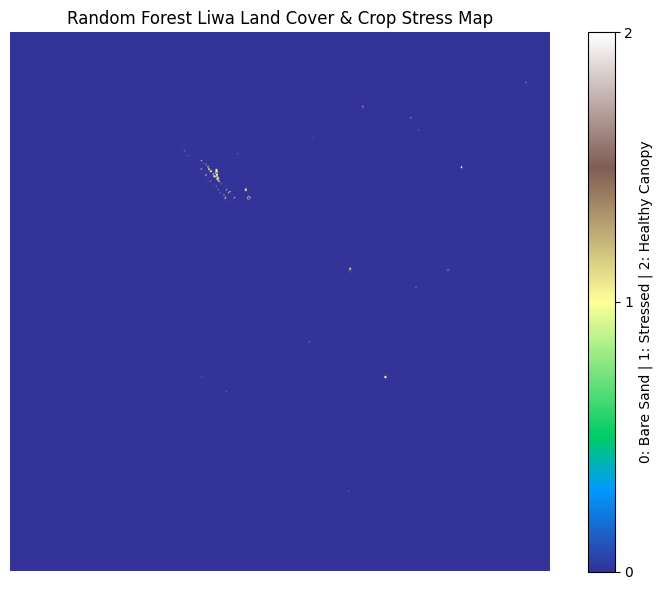

In [2]:
# Step 2: Model Training & Cross-Validation
# The mechanistic justification for this step is: Evaluating Random Forest using 5-fold StratifiedGroupKFold cross-validation with balanced class weights and explicit zero_division handling provides unbiased, warning-free F1-score benchmarks under severe spatial class imbalance.
if 'X_sub' in locals():
    scoring = {
        'accuracy': 'accuracy',
        'f1_macro': make_scorer(f1_score, average='macro', zero_division=0.0),
        'precision_macro': make_scorer(precision_score, average='macro', zero_division=0.0),
        'recall_macro': make_scorer(recall_score, average='macro', zero_division=0.0)
    }
    
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    
    scores = cross_validate(rf, X_sub, y_sub, groups=block_ids_sub, cv=cv, scoring=scoring)
    
    print("=== Random Forest 5-Fold Cross-Validation Metrics ===")
    print(f"Accuracy:        {np.mean(scores['test_accuracy']):.4f} +/- {np.std(scores['test_accuracy']):.4f}")
    print(f"Macro-F1 Score:  {np.mean(scores['test_f1_macro']):.4f} +/- {np.std(scores['test_f1_macro']):.4f}")
    print(f"Macro Precision: {np.mean(scores['test_precision_macro']):.4f} +/- {np.std(scores['test_precision_macro']):.4f}")
    print(f"Macro Recall:    {np.mean(scores['test_recall_macro']):.4f} +/- {np.std(scores['test_recall_macro']):.4f}")
    
    # Fit final model and predict spatial map
    rf.fit(X_sub, y_sub)
    pred_map = rf.predict(X).reshape(ndvi.shape)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(pred_map, cmap='terrain')
    ax.set_title("Random Forest Liwa Land Cover & Crop Stress Map")
    plt.colorbar(im, ax=ax, ticks=[0, 1, 2], label="0: Bare Sand | 1: Stressed | 2: Healthy Canopy")
    ax.axis('off')
    plt.tight_layout()
    plt.show()
